# Example: RMDC26_000209 — a blind Roman event with a short planetary-caustic spike

The sixth blind example on simulated Roman data, after `example_rmdc26_000026` (a planetary caustic),
`example_rmdc26_001422` (a central caustic with a close/wide degeneracy), `example_rmdc26_001576` (a resonant
caustic), `example_rmdc26_001279` (a cusp approach at high magnification) and `example_rmdc26_001532` (a double
peak). This one is the quiet kind: a low-magnification event (the source is magnified about 3 times at the peak, and the flux, dominated by other stars, rises by only 30 %)
with a single **one-and-a-half-hour spike** almost seven days before the peak, where the source crosses the small caustic of
a planet far outside the Einstein ring.

What it shows:

* **The anomaly time says where the planet is.** The spike happens when the source is 1.37 Einstein radii from the
  host; a wide planet with *s* − 1/*s* ≈ 1.37 puts its caustic there. The angle screen at the single-lens
  trajectory finds this directly; no caustic-crossing starts are needed.
* **One clean minimum.** The coarse map has one deep valley, the 8× zoom resolves it, and a 64× zoom only confirms
  it. Close solutions (a planet inside the Einstein ring) are worse by more than 200.

**The data.** RMDC26_000209 is an event of the *Experienced tier* of the Roman Microlensing Data Challenge 2026
(RGES-PIT; public domain, CC0, [huggingface.co/datasets/RGES-PIT/Experienced](https://huggingface.co/datasets/RGES-PIT/Experienced)),
simulated with GULLS (Penny et al. 2019). The true parameters are not published, so this is a **blind** analysis.
The field is heavily reddened (8.2, 3.3 and 1.1 mag of extinction in F087, F146 and F213): F087 is almost pure noise,
and F146 carries the event.

**Runtime.** On a 14-core Intel Core i5-13500 (20 threads): guided fits 3 minutes, coarse map 15 minutes, zooms
18 + 83 + 2 minutes, polish 2 minutes. Everything is stored in `data/`, so the notebook runs in a few seconds
by default; `RECOMPUTE = True` computes it all again (about 2 hours; the guided fits run serially there and
take longer).

## 0. Setup

In [1]:
import os, time, json
import numpy as np
import matplotlib.pyplot as plt
import lenscape
from lenscape import figures, caustics, model

RECOMPUTE = False              # True: compute all maps and fits again (a few hours on a 20-thread desktop)
LOGFILE = os.environ.get("LENSCAPE_LOG")          # progress of long runs is also appended here if set


def log(msg):
    print(msg, flush=True)
    if LOGFILE:
        with open(LOGFILE, "a") as f:
            f.write(f"{time.strftime('%H:%M:%S')} {msg}\n")

print("lenscape", lenscape.__version__)

lenscape 1.0


## 1. The photometry

`data/rmdc0209_photometry.csv`: all unsaturated points, with `set` (filter), `t` (BJD − 2460000) and `flux`,
`flux_err` in micro-Jansky as provided. Magnitudes below are AB, 23.9 − 2.5 log₁₀(flux / µJy).

In [2]:
SETS = ["F087", "F146", "F213"]
rows = np.genfromtxt("data/rmdc0209_photometry.csv", delimiter=",", names=True, dtype=None, encoding="utf-8",
                     skip_header=3)                     # the first three lines are comments
sel = lambda r, n: (r["t"][r["set"] == n], r["flux"][r["set"] == n], r["flux_err"][r["set"] == n])
data_all = lenscape.Data.from_sets({n: sel(rows, n) for n in SETS})
mag = lambda f: 23.9 - 2.5 * np.log10(f)                # AB magnitude of a flux in micro-Jansky
for n in SETS:
    t, f, e = sel(rows, n)
    print(f"{n}: {len(t)} points, median flux {np.median(f):9.4f} uJy, median error {np.median(e):.4f} uJy")

F087: 1501 points, median flux    0.1794 uJy, median error 0.2742 uJy
F146: 46488 points, median flux   10.1292 uJy, median error 0.1954 uJy
F213: 1499 points, median flux  117.8363 uJy, median error 0.9595 uJy


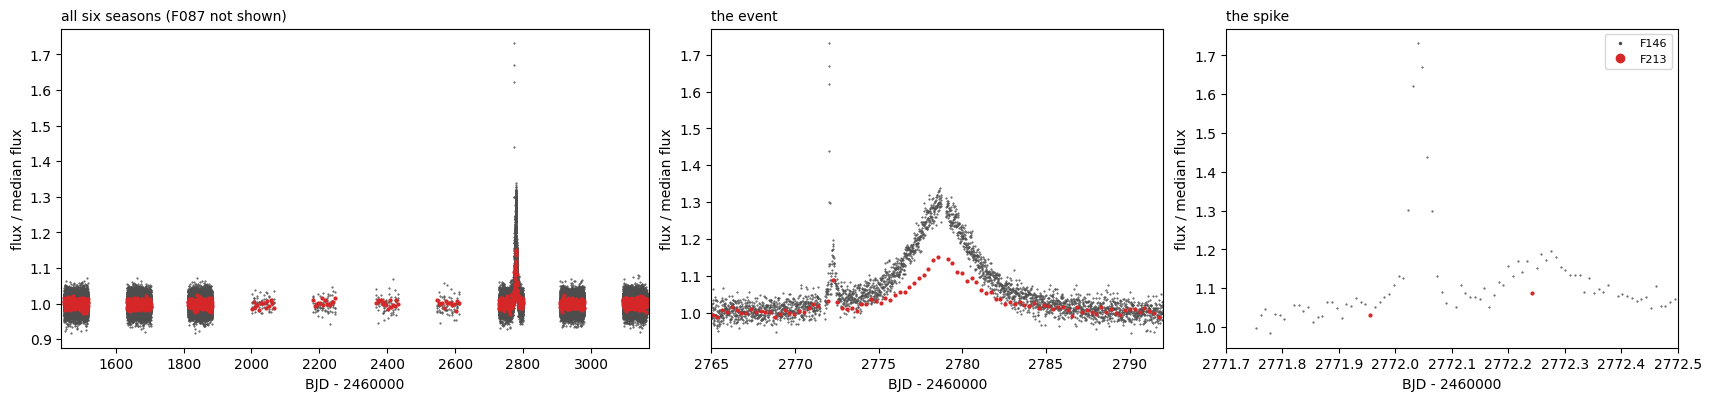

In [3]:
fig, axs = plt.subplots(1, 3, figsize=(17, 3.9), gridspec_kw=dict(width_ratios=[1.3, 1, 1]), constrained_layout=True)
for ax, (a, b) in zip(axs, ((1440, 3170), (2765, 2792), (2771.7, 2772.5))):
    for n, c in (("F146", "0.3"), ("F213", "C3")):
        k = data_all.names.index(n)
        m = (data_all.idx == k) & (data_all.t > a) & (data_all.t < b)
        ax.plot(data_all.t[m], data_all.f[m] / np.median(data_all.f[data_all.idx == k]), ".", ms=1 if n == "F146" else 4,
                color=c, label=n, rasterized=True)
    ax.set_xlim(a, b); ax.set_xlabel("BJD - 2460000"); ax.set_ylabel("flux / median flux")
axs[0].set_title("all six seasons (F087 not shown)", loc="left", fontsize=10)
axs[1].set_title("the event", loc="left", fontsize=10)
axs[2].set_title("the spike", loc="left", fontsize=10); axs[2].legend(fontsize=8, markerscale=3)

The event is in the last season. It is faint: the flux rises by only 30 % at the peak (BJD′ = 2778.7,
BJD′ = BJD − 2460000) and the curve is smooth there. The interesting part comes 6.6 days earlier: at BJD′ 2772.05
the flux jumps by 70 % within an hour and falls back within another, a spike seen in about ten F146 points. F087 is
not plotted; with 8 mag of extinction its points scatter by several times the baseline flux. It is kept in the fits,
where it weighs little.

## 2. Reducing the data for the maps

The same reduction as in the other examples: the event season only (BJD′ 2728–2800), F146 at full cadence over
the spike (BJD′ 2771.6–2772.8), in 1-hour bins within one Einstein timescale of the single-lens screen fit
(*t*₀ = 2778.69, *t*ₑ = 7.15 d) and 3-hour bins elsewhere; F087 and F213 unbinned.

In [4]:
SEASON = (2728.0, 2800.0)
ANOM = (2771.6, 2772.8)
T0_BIN, TE_BIN = 2778.69, 7.15
def reduce(rows):
    # season only; F146: full cadence in ANOM, 1-h bins within TE_BIN of T0_BIN, 3-h bins elsewhere
    out = {}
    for n in SETS:
        t, f, e = sel(rows, n)
        m = (t >= SEASON[0]) & (t <= SEASON[1])
        t, f, e = t[m], f[m], e[m]
        if n != "F146":
            out[n] = (t, f, e); continue
        full = (t >= ANOM[0]) & (t <= ANOM[1])
        inner = np.abs(t - T0_BIN) < TE_BIN
        key = np.floor((t - SEASON[0]) / np.where(inner, 1 / 24, 3 / 24)).astype(int) * 2 + inner
        b = ~full
        u, inv = np.unique(key[b], return_inverse=True)
        w = 1 / e[b] ** 2
        W = np.bincount(inv, w)
        T, F, E = (np.r_[t[full], np.bincount(inv, w * t[b]) / W], np.r_[f[full], np.bincount(inv, w * f[b]) / W],
                   np.r_[e[full], W ** -0.5])
        o = np.argsort(T)
        out[n] = (T[o], F[o], E[o])
    return lenscape.Data.from_sets(out)

data = reduce(rows)
season = data_all.window(*SEASON)
be = lenscape.make_backend(lenscape.config.REFINE_BACKEND)
print(f"all {len(data_all)} points, season {len(season)}, binned {len(data)}:",
      {n: len(s) for n, s in zip(data.names, data.slices)})

all 49488 points, season 8181, binned 1348: {'F087': 240, 'F146': 868, 'F213': 240}


## 3. The single lens and what the spike says

A point lens with a finite source, fitted with the spike masked, gives *t*₀ = 2778.71, *u*₀ ≈ 0.31 and
*t*ₑ ≈ 5.2 d. At the time of the spike the source is then |*u*| = √(((2772.05 − 2778.71) / 5.2)² + 0.31²) ≈ 1.3
Einstein radii from the host. A short, isolated spike far from the peak is the signature of a **planetary
caustic**: a planet at separation *s* has one small caustic at a distance |*s* − 1/*s*| from the host, on the
planet's side if *s* > 1 (one diamond-shaped caustic) and on the opposite side if *s* < 1 (two small triangles,
which a source passes more rarely). |*s* − 1/*s*| ≈ 1.3 gives *s* ≈ 1.9 or *s* ≈ 0.53 (Gould & Loeb 1992;
Han 2006). The spike's height and duration then set *q* and the source size.

## 4. Guided fits

At log *s* = ±0.05, ±0.1, ±0.2, ±0.3, ±0.5 and ±0.8, every log *q* from −5 to 0 (steps of 0.5) and three source sizes,
360 trajectory angles are tried at the single-lens trajectory (143 000 trial light curves, 10 s on 20 cores). The 24
best distinct starts are fitted in all seven parameters (`lenscape.fit_full`), then the offset-degenerate partner
(`lenscape.fit.offset_partner`) of the 8 best results. The fits were run in parallel (3 minutes); the stored results
are loaded here (`RECOMPUTE = True` runs them again, serially).

In [5]:
first_file = "data/rmdc0209_first_fits.json"
if RECOMPUTE or not os.path.exists(first_file):
    log("computing the guided fits")
    from scipy.optimize import minimize
    m = data.select(~((data.t >= ANOM[0]) & (data.t <= ANOM[1])))
    def c2_single(x):
        A = lenscape.single.lc_1l1s(x[0], x[1], abs(x[2]) + 1e-3, 10 ** min(x[3], -0.5), m.t, 0.0)
        return model.chi2_profiled(A, m.f, m.w, m.idx, m.nsets)
    r = min((minimize(c2_single, [2778.69, u0, tE, -2.5], method="Nelder-Mead", options=dict(maxfev=4000, adaptive=True))
             for u0 in (0.02, 0.05, 0.1) for tE in (5.0, 10.0, 20.0)), key=lambda r: r.fun)
    sl = dict(t0=float(r.x[0]), u0=abs(float(r.x[1])), tE=abs(float(r.x[2])) + 1e-3)
    grid = lenscape.make_backend(lenscape.config.GRID_BACKEND)
    trials = []
    for ls in [v * sg for v in (0.05, 0.1, 0.2, 0.3, 0.5, 0.8) for sg in (1, -1)]:
        for lq in np.arange(-5.0, 0.01, 0.5):
            for lr in (-3.0, -2.5, -2.0):
                for a in np.arange(360) * 2 * np.pi / 360:
                    p = [sl["t0"], sl["u0"], sl["tE"], ls, float(lq), float(a), lr]
                    trials.append((model.chi2(grid, p, data), p))
    trials.sort(key=lambda r: r[0])
    def distinct(rows, n, ds, dq, da):
        out = []
        for c, p in rows:
            if all(abs(p[3] - q[3]) > ds or abs(p[4] - q[4]) > dq or abs(np.angle(np.exp(1j * (p[5] - q[5])))) > da
                   for _, q in out):
                out.append((c, p))
            if len(out) == n:
                break
        return out
    def full_fit(p):
        c, p = lenscape.fit_full(data, p, grid, rounds=2, maxfev=3000)
        c, p = lenscape.fit_full(data, p, be, rounds=2, maxfev=3000)
        return float(c), [float(v) for v in p]
    res = sorted((full_fit(p) for _, p in distinct(trials, 24, 0.01, 0.1, 0.15)), key=lambda r: r[0])
    res += [full_fit(lenscape.fit.offset_partner(np.array(p)).tolist()) for _, p in distinct(res, 8, 0.005, 0.05, 0.1)]
    json.dump(dict(single_lens=sl, fits=sorted(res, key=lambda r: r[0])), open(first_file, "w"), indent=1)
first = json.load(open(first_file))
sl = first["single_lens"]
print(f"single lens (spike masked): t0 = {sl['t0']:.3f}, u0 = {sl['u0']:.4f}, tE = {sl['tE']:.2f} d")
print(f"{'chi2':>9s} {'log s':>8s} {'log q':>7s} {'alpha':>6s} {'u0':>8s} {'tE':>7s} {'log rho':>7s}")
shown = []
for c, p in first["fits"]:
    if all(abs(p[3] - q[3]) > 0.003 or abs(p[4] - q[4]) > 0.03 for _, q in shown):
        shown.append((c, p))
        print(f"{c:9.2f} {p[3]:+8.4f} {p[4]:+7.3f} {p[5] % (2 * np.pi):6.3f} {p[1]:+8.5f} {p[2]:7.3f} {p[6]:+7.3f}")
    if len(shown) == 12:
        break
best_first = np.array(first["fits"][0][1])
close_first = np.array([p for c, p in first["fits"] if p[3] < 0][0])

single lens (spike masked): t0 = 2778.713, u0 = 0.3131, tE = 5.18 d
     chi2    log s   log q  alpha       u0      tE log rho
  1386.61  +0.2793  -2.862  0.252 +0.32814   4.990  -2.457
  1603.40  -0.2963  -1.402  3.889 +0.43352   4.530  -2.706
  1698.59  -0.3018  -1.537  3.810 +0.43078   4.473  -2.698
  1866.13  -0.4027  -0.182  4.759 +0.56033   2.968  -2.230
  1892.55  -0.4319  +0.194  1.624 +0.65896   2.760  -2.253
  1938.92  -0.3504  -0.894  2.641 +0.46224   3.708  -2.496
  1949.32  -0.2447  -1.209  2.745 +0.21319   5.714  -2.961
  2004.57  -0.2698  -1.002  2.635 +0.25513   5.044  -3.041
  2044.42  -0.3375  -1.281  2.906 +0.46676   3.975  -2.607
  2109.59  -0.2857  -0.883  2.559 +0.27935   4.685  -3.033
  2321.46  -0.2616  -2.652  3.266 +0.30208   5.342  -3.450
  2358.20  +0.2856  -2.366  0.216 +0.33252   4.856  -2.434


One fit stands out: **wide**, log *s* = +0.279 (*s* = 1.90), log *q* = −2.86, χ² = 1386.6 for 1348 binned points. The
best **close** fit (log *s* = −0.296, the triangles of a planet inside the Einstein ring, with a much larger
*q* ≈ 0.04) is 217 worse; all other fits are worse by 300 or more. The single lens with the spike is 5000 worse.

The binning is checked as in the other examples: the Δχ² between the wide and close fits is about the same on the
binned data, the unbinned season and all six seasons.

In [6]:
check = {"wide": best_first, "close": close_first}
c = {k: [model.chi2(be, p, d) for d in (data, season, data_all)] for k, p in check.items()}
print(f"{'':7s} {'binned':>10s} {'season':>10s} {'all':>10s}   (Delta chi2 to the wide fit)")
for k, v in c.items():
    print(f"{k:7s} " + " ".join(f"{a - b:10.2f}" for a, b in zip(v, c["wide"])))
print(f"wide fit: chi2 = {c['wide'][0]:.1f} (binned, N = {len(data)}), {c['wide'][1]:.1f} (season, N = {len(season)}), "
      f"{c['wide'][2]:.1f} (all, N = {len(data_all)})")

            binned     season        all   (Delta chi2 to the wide fit)
wide          0.00       0.00       0.00
close       216.78     216.17     216.45
wide fit: chi2 = 1386.6 (binned, N = 1348), 8097.2 (season, N = 8181), 49471.8 (all, N = 49488)


## 5. The coarse map

The same lattice as before: −1 ≤ log *s* ≤ 1 in steps of 0.04, −5 ≤ log *q* ≤ 0 in steps of 0.1, 51 × 51
points, no refinement more than 500 above the minimum. **Runtime: 15 minutes.**

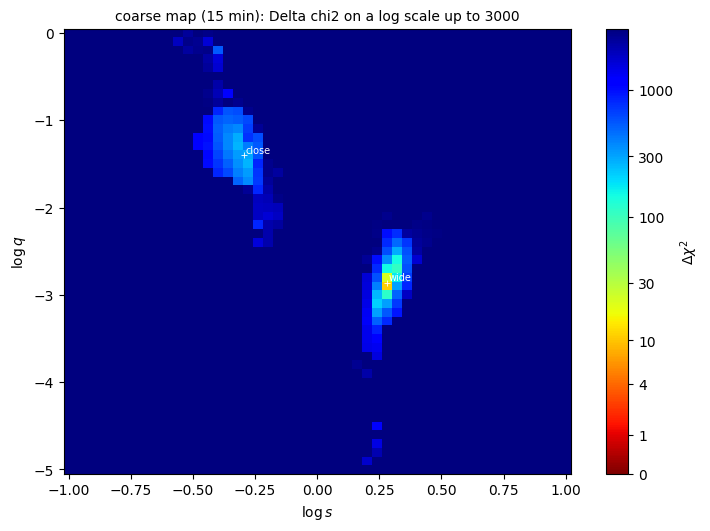

In [7]:
KEYS = ("logs", "logq", "chi2", "pars", "chi2_ref", "wall")


def run_or_load(name, compute):
    # data/rmdc0209_map_NAME.npz: computed (and saved) if missing or RECOMPUTE, else loaded
    path = f"data/rmdc0209_map_{name}.npz"
    if RECOMPUTE or not os.path.exists(path):
        log(f"computing map {name}")
        m = compute()
        np.savez_compressed(path, **{k: m[k] for k in KEYS})
        log(f"map {name}: {m['chi2'].shape}, {m['wall'] / 60:.1f} min, lowest chi2 {np.nanmin(m['chi2']):.2f}")
        return m
    return dict(np.load(path))

logs1 = np.round(np.arange(-1.0, 1.0001, 0.04), 4)
logq1 = np.round(np.arange(-5.0, 0.0001, 0.1), 4)
map1 = run_or_load("1x", lambda: lenscape.lattice(data, logs1, logq1, best=best_first, bin_wings=False, dchi2_cut=5.0,
                                                  log=log))
ref0 = first["fits"][0][0]
fig, ax = plt.subplots(figsize=(7, 5.2), constrained_layout=True)
figures.plot_map(map1, ax=ax, vmax=3000, chi2_ref=ref0, marks={"wide": best_first[3:5], "close": close_first[3:5]})
ax.set_title(f"coarse map ({map1['wall'] / 60:.0f} min): Delta chi2 on a log scale up to 3000", fontsize=10);

Most of the map lies above Δχ² = 3000 (dark blue): there a planet cannot make the spike. Three regions do
better. The deepest is a narrow tilted valley at log *s* ≈ 0.25–0.32, from log *q* ≈ −4 to −2.2; its
lowest lattice point, at (0.28, −2.9), is 11 above the guided fit. Along the valley the planetary caustic stays at
the right place (|*s* − 1/*s*| ≈ 1.3–1.4), and *q* changes its size. A second region, at log *s* ≈ −0.3 and
log *q* ≈ −1.5, holds the close solutions (Δχ² ≈ 260 at the lattice), and a third, smaller one at
log *s* ≈ −0.4, log *q* ≈ −0.2, is a stellar binary (Δχ² ≈ 540).

## 6. Zooming into the valleys

`lenscape.maps.densify` refines boxes aligned with the coarse lattice: the wide valley at 8× in log *s* and 4× in
log *q* (0.005 × 0.025), then its minimum at 64× × 16× (0.000625 × 0.00625); the close region at 4× × 4×
(0.01 × 0.025).

In [8]:
step = lambda lo, hi, x0, st: np.round(x0 + st * np.arange(int(np.ceil((lo - x0) / st - 1e-9)),
                                                           int(np.floor((hi - x0) / st + 1e-9)) + 1), 6)
dens = lambda prev, s, q, fs, fq: lenscape.maps.densify(prev, data, step(*s, -1.0, 0.04 / fs), step(*q, -5.0, 0.1 / fq),
                                                         best=best_first, bin_wings=False, log=log)
mapw8 = run_or_load("wide_8x", lambda: dens([map1], (0.20, 0.40), (-3.5, -2.2), 8, 4))
mapc4 = run_or_load("close_4x", lambda: dens([map1], (-0.44, -0.20), (-1.9, -0.8), 4, 4))
mapw64 = run_or_load("wide_64x", lambda: dens([mapw8, map1], (0.265, 0.290), (-2.95, -2.775), 64, 16))
MAPS = [("coarse", map1), ("wide 8x", mapw8), ("close 4x", mapc4), ("wide 64x", mapw64)]
ref = min(np.nanmin(m["chi2"]) for _, m in MAPS)
for name, m in MAPS:
    i, j = np.unravel_index(np.nanargmin(m["chi2"]), m["chi2"].shape)
    print(f"{name:10s}: {m['chi2'].shape[0]:2d} x {m['chi2'].shape[1]:2d} points, {m['wall'] / 60:4.1f} min, lowest point "
          f"{m['chi2'][i, j] - ref:7.2f} at log s = {m['logs'][i]:+.6f}, log q = {m['logq'][j]:.5f}")

coarse    : 51 x 51 points, 14.6 min, lowest point   10.97 at log s = +0.280000, log q = -2.90000
wide 8x   : 41 x 53 points, 18.2 min, lowest point    0.49 at log s = +0.280000, log q = -2.85000
close 4x  : 25 x 45 points, 83.0 min, lowest point  219.85 at log s = -0.300000, log q = -1.37500
wide 64x  : 41 x 29 points,  2.3 min, lowest point    0.00 at log s = +0.279375, log q = -2.86250


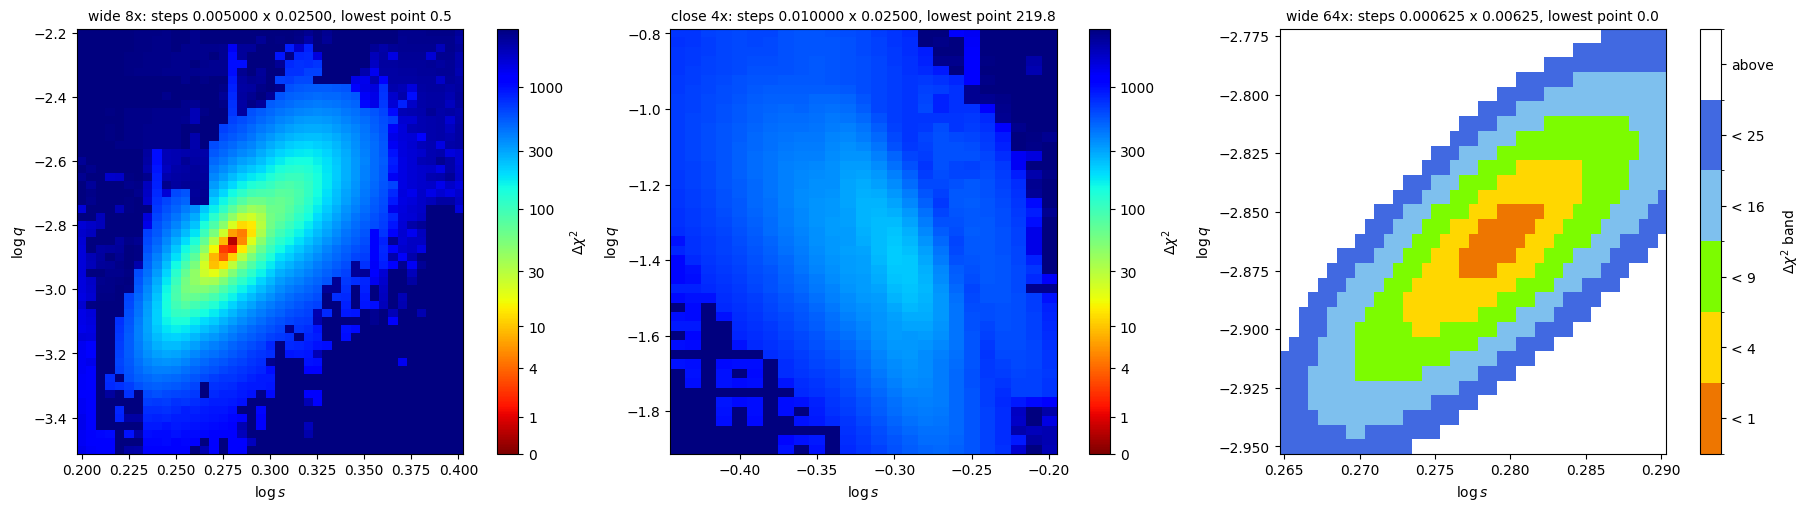

In [9]:
fig, axs = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)
for ax, (name, m) in zip(axs, MAPS[1:]):
    if name.endswith(" 64x"):
        figures.plot_map(m, bands=(1, 4, 9, 16, 25), ax=ax, chi2_ref=ref)
    else:
        figures.plot_map(m, ax=ax, vmax=3000, chi2_ref=ref)
    ax.set_title(f"{name}: steps {m['logs'][1] - m['logs'][0]:.6f} x {m['logq'][1] - m['logq'][0]:.5f}, "
                 f"lowest point {np.nanmin(m['chi2']) - ref:.1f}", fontsize=10)

Left: the 8× box over the wide valley, on a log scale up to 3000. The valley is a smooth, tilted trough; its
lowest point is already within 0.5 of the global minimum. Right: the 64× box around that point, with Δχ² bands
1, 4, 9, 16, 25. It shows a single elliptical minimum at log *s* = +0.2794, log *q* = −2.863, tilted so that a larger
*q* goes with a larger *s*: a larger planet makes a larger caustic, which the source must cross at the same time, so
the caustic moves outwards. Δχ² < 4 spans log *s* 0.273–0.284 and log *q* −2.90 … −2.83 (about ±0.006 and
±0.035 dex). The 64× box adds no new structure; for this event the 8× zoom was enough. Middle: the close region at
4×. Its lowest point is 220 above the wide minimum, at log *s* = −0.30, log *q* = −1.375.

## 7. The best fit

In [10]:
best_file = "data/rmdc0209_best.json"
if RECOMPUTE or not os.path.exists(best_file):
    log("polishing the two solutions")
    out = {}
    for name, m, extra in (("wide", mapw64, best_first), ("close", mapc4, close_first)):
        i, j = np.unravel_index(np.nanargmin(m["chi2"]), m["chi2"].shape)
        x = m["pars"][i, j]
        starts = [np.array([x[0], x[1], x[2], m["logs"][i], m["logq"][j], x[3], x[4]]), extra]
        c_b, p_b = min((lenscape.fit_full(data, p, be, rounds=3, maxfev=6000) for p in starts), key=lambda r: r[0])
        c_s, p_s = lenscape.fit_full(season, p_b, be, rounds=2, maxfev=4000)
        out[name] = dict(p_binned=list(p_b), p_season=list(p_s))
    json.dump(dict(p_binned=out["wide"]["p_binned"], p_season=out["wide"]["p_season"], close=out["close"]),
              open(best_file, "w"), indent=1)
bj = json.load(open(best_file))
best, close = np.array(bj["p_season"]), np.array(bj["close"]["p_season"])
for name, p in (("wide", best), ("close", close)):
    print(f"{name}: t0 = {p[0]:.4f}, u0 = {p[1]:+.5f}, tE = {p[2]:.3f} d, s = {10 ** p[3]:.5f}, q = {10 ** p[4]:.4e}, "
          f"alpha = {p[5] % (2 * np.pi):.4f}, rho = {10 ** p[6]:.3e}")
    print(f"       chi2 season {model.chi2(be, p, season):.1f} (N = {len(season)}), all {model.chi2(be, p, data_all):.1f} "
          f"(N = {len(data_all)})")
r = model.residuals(be, best, season)
for k, n in enumerate(season.names):
    print(f"  wide, {n}: chi2 / N = {np.sum(r[season.idx == k] ** 2):.1f} / {np.sum(season.idx == k)}")
fs, fb = model.fluxes(model.magnification(be, best, season), season)
for k, n in enumerate(season.names):
    print(f"  {n}: source flux {fs[k]:8.4f} uJy ({mag(fs[k]) if fs[k] > 0 else np.nan:.2f} AB), "
          f"blend {fb[k]:8.4f} uJy ({mag(fb[k]) if fb[k] > 0 else np.nan:.2f} AB)")

wide: t0 = 2778.7029, u0 = +0.32806, tE = 4.990 d, s = 1.90227, q = 1.3759e-03, alpha = 0.2515, rho = 3.491e-03
       chi2 season 8097.2 (N = 8181), all 49471.8 (N = 49488)
close: t0 = 2778.6098, u0 = +0.43351, tE = 4.530 d, s = 0.50549, q = 3.9593e-02, alpha = 3.8892, rho = 1.968e-03
       chi2 season 8313.4 (N = 8181), all 49688.2 (N = 49488)
  wide, F087: chi2 / N = 261.5 / 240
  wide, F146: chi2 / N = 7606.2 / 7701
  wide, F213: chi2 / N = 229.5 / 240
  F087: source flux   0.0306 uJy (27.68 AB), blend   0.1600 uJy (25.89 AB)
  F146: source flux   1.3847 uJy (23.55 AB), blend   8.7341 uJy (21.55 AB)
  F213: source flux   7.8420 uJy (21.66 AB), blend 109.9304 uJy (18.80 AB)


| parameter | wide (best) | close |
|---|---|---|
| *t*₀ (BJD′) | 2778.703 | 2778.610 |
| *u*₀ | +0.328 | +0.434 |
| *t*ₑ | 4.99 d | 4.53 d |
| *s* | 1.903 | 0.505 |
| *q* | 1.37 × 10⁻³ | 3.96 × 10⁻² |
| α | 0.252 rad | 3.889 rad |
| ρ | 3.49 × 10⁻³ | 1.97 × 10⁻³ |
| χ² (all 49 488 points) | 49 471.8 | +216 |

χ²/N is 1.09, 0.99 and 0.96 in F087, F146 and F213 (season). The close solution is the best guided close fit;
polishing from the lowest point of the close 4× box did not improve on it. It is worse by Δχ² = 216 on the binned
data, the season and all six seasons alike, so the wide solution is clearly preferred.

The source is faint, 23.55 mag in F146 (AB), and the blend is 2 mag brighter (21.55). That is why a magnification
of 3.2 at the peak raises the total flux by only 30 %.

## 8. The light curve

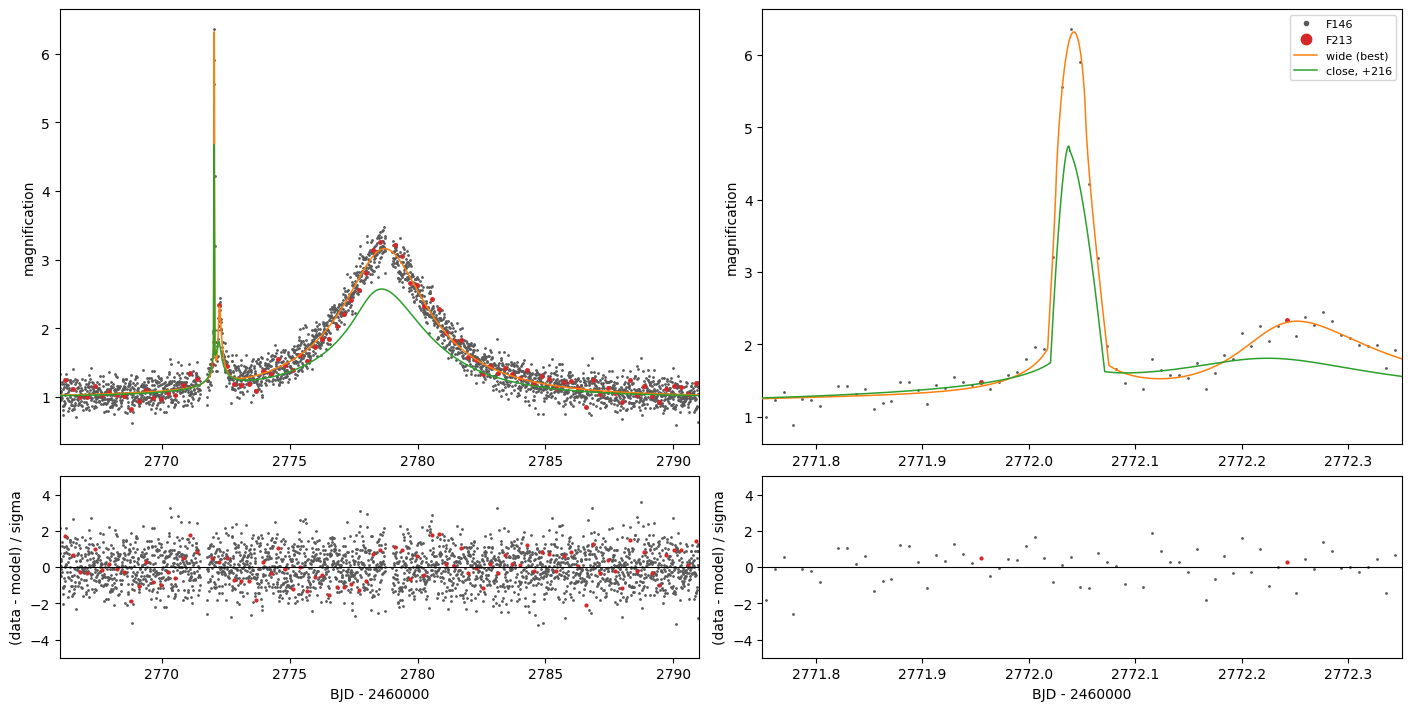

In [11]:
def plot_lc(sols, d=season, window=(2766, 2791), zoom=(2771.75, 2772.35)):
    # F146 and F213 as magnifications implied by each point (for the first solution); models; residuals of the first
    p = sols[0][1]
    fs, fb = model.fluxes(model.magnification(be, p, d), d)
    fig = plt.figure(figsize=(14, 7), constrained_layout=True)
    gs = fig.add_gridspec(2, 2, height_ratios=[2.4, 1])
    res = model.residuals(be, p, d)
    for col, (a, b) in enumerate((window, zoom)):
        ax, axr = fig.add_subplot(gs[0, col]), fig.add_subplot(gs[1, col])
        for k, (n, c) in enumerate(zip(d.names, ["C0", "0.35", "C3"])):
            if n == "F087":
                continue
            m = (d.idx == k) & (d.t > a) & (d.t < b)
            ax.plot(d.t[m], (d.f[m] - fb[k]) / fs[k], ".", ms=2 if n == "F146" else 5, color=c, label=n, zorder=2)
            axr.plot(d.t[m], res[m], ".", ms=2 if n == "F146" else 4, color=c)
        tt = np.linspace(a, b, 6000)
        for (lab, q), c in zip(sols, ("C1", "C2")):
            ax.plot(tt, be.lc(model.clamp(q)[0], tt), color=c, lw=1.1, label=lab, zorder=3)
        ax.set_xlim(a, b); ax.set_ylabel("magnification")
        axr.axhline(0, color="k", lw=0.8); axr.set_xlim(a, b); axr.set_ylim(-5, 5)
        axr.set_ylabel("(data - model) / sigma"); axr.set_xlabel("BJD - 2460000")
    ax.legend(fontsize=8, markerscale=3)
    return fig

plot_lc([("wide (best)", best), (f"close, +{model.chi2(be, close, season) - model.chi2(be, best, season):.0f}", close)]);

Drawn as magnification (each point's flux with the fitted blend removed, divided by the source flux). Left: the
whole event, a smooth single-lens peak of magnification 3.2 at BJD′ 2778.7 and the spike 6.6 days before it.
Right: the spike. The magnification rises from 1.9 to 6.3 at BJD′ 2772.04 and falls back within 1.5 hours
(2772.02–2772.08); about 0.2 day later a small, broad bump to 2.3 follows (BJD′ 2772.25). The residuals are flat.
The close solution (green) makes a spike too, but it is too low, it lacks the second bump and, on the left, it
also misses the height of the main peak (2.6 instead of 3.2).

## 9. The caustic and the source trajectory

planetary caustic: centre x = 1.3763, y = -0.0000 (host at the origin), width 0.0482 Einstein radii


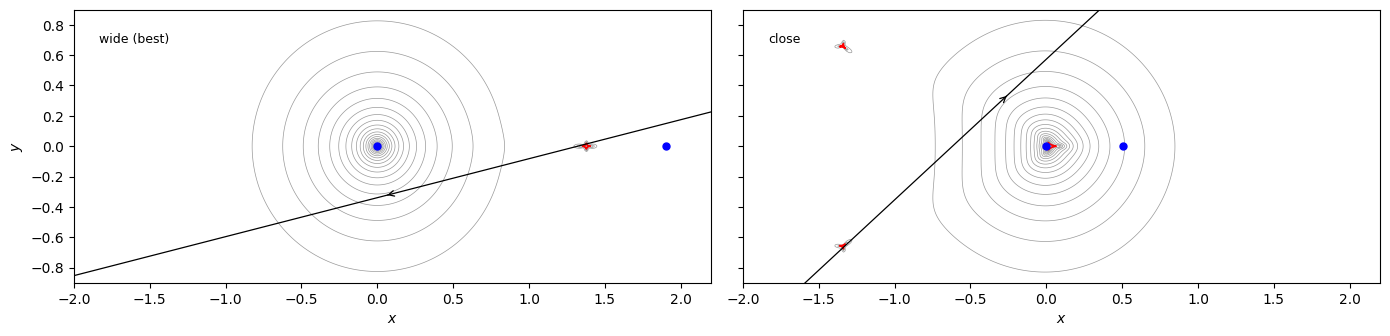

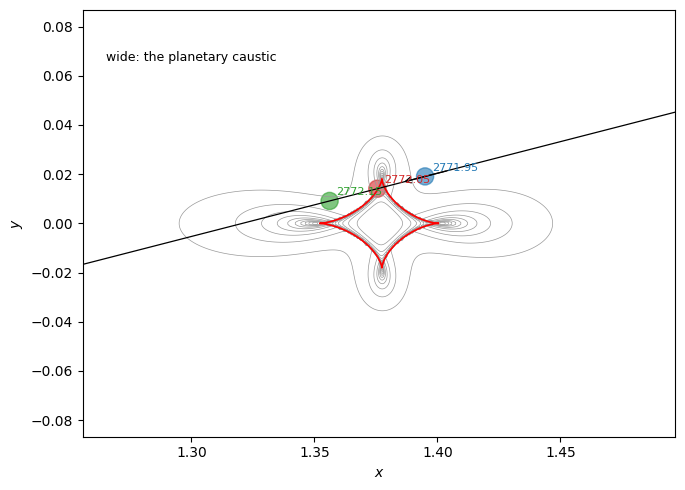

In [12]:
x0 = caustics.lens_positions(10 ** best[3], 10 ** best[4])[0]
zc = np.concatenate(caustics.caustics(10 ** best[3], 10 ** best[4], 2000))
pc = zc[np.abs(zc.real - x0) > 0.5]                      # the planetary caustic
cx, cy, w = (pc.real.min() + pc.real.max()) / 2 - x0, (pc.imag.min() + pc.imag.max()) / 2, np.ptp(pc.real)
print(f"planetary caustic: centre x = {cx:.4f}, y = {cy:.4f} (host at the origin), width {w:.4f} Einstein radii")
fig = figures.plot_geometry([best, close], labels=["wide (best)", "close"], ncols=2, figsize=(14, 4.6),
                            extent=(-2.0, 2.2, -0.9, 0.9))
fig = figures.plot_geometry([best], labels=["wide: the planetary caustic"], ncols=1, figsize=(7, 5),
                            extent=(cx - 2.5 * w, cx + 2.5 * w, cy - 1.8 * w, cy + 1.8 * w), t_arrow=2771.9)
ax = fig.axes[0]
for t, c in ((2771.95, "C0"), (2772.05, "C3"), (2772.15, "C2")):
    z = caustics.trajectory(best, [t])[0]
    ax.add_patch(plt.Circle((z.real - x0, z.imag), 10 ** best[6], color=c, alpha=0.6))
    ax.annotate(f"{t:.2f}", (z.real - x0, z.imag), xytext=(5, 4), textcoords="offset points", fontsize=8, color=c)

Top: the whole system. In the wide solution (left) the planet sits at 1.90 Einstein radii from the host (at
the origin); the central caustic at the host is tiny (0.003 Einstein radii), and the planetary caustic lies at
*x* ≈ 1.35–1.40, between host and planet. The source passes the host at 0.33 Einstein radii and, on its way in,
cuts through the planetary caustic. In the close solution (right) the planet is inside the Einstein ring and its two
small triangular caustics lie on the far side of the host, at *x* ≈ −1.35 and *y* ≈ ±0.65; the spike comes from
the source crossing the lower one.

Bottom: the planetary caustic of the wide solution, a diamond 0.048 Einstein radii long and 0.036 wide. The source
(discs at three times; it moves from right to left) cuts across the caustic's **upper cusp**, inside the caustic
for only about 1.5 hours (BJD′ 2772.02–2772.08); a short path through a cusp gives a sharp spike rather than the
flat-topped box of a crossing through the middle. It then passes close to the left (on-axis) cusp, which makes
the small second bump at BJD′ 2772.25. The source radius, 0.0035 Einstein radii, is comparable to the size of
the cusp region it crosses, so the spike's shape fixes ρ.

## 10. What kind of system is this?

**Measured.** A planet with *q* = 1.37 × 10⁻³ of its host's mass (1.4 times the Jupiter–Sun ratio) at
*s* = 1.90 Einstein radii, well outside the Einstein ring. *t*ₑ = 5.0 d, and the source takes
ρ *t*ₑ = 25 minutes to cross its radius.

**Physical scale (rough).** The fit gives the source 23.55 mag in F146 (AB). With the challenge's extinction
(3.27 mag) and a source at 8 kpc, its absolute F146 magnitude is 5.8, about one magnitude fainter than the Sun in
the near infrared (*H*_AB ≈ 4.7). With the Sun's surface brightness that is about 0.6 solar radii (a K or early M
dwarf; only an order of magnitude), and θ⋆ ≈ 0.36 µas. With ρ that gives θₑ ≈ 0.10 mas and a relative proper motion
μ ≈ 7 mas/yr.

In [13]:
A146 = 3.27                                    # extinction in F146 from the challenge's photometry table
M146 = mag(fs[1]) - A146 - 5 * np.log10(8000 / 10)                # source at 8 kpc
theta_s = 0.581e-3 * 10 ** (-(M146 - 4.71) / 5)                   # mas; 0.581 micro-arcsec = 1 R_sun at 8 kpc
theta_E = theta_s / 10 ** best[6]
DS = 8.0
print(f"M_F146 = {M146:.2f}, R ~ {10 ** (-(M146 - 4.71) / 5):.2f} R_sun, theta_* = {theta_s * 1e3:.3f} micro-arcsec, "
      f"theta_E = {theta_E:.4f} mas, mu_rel = {theta_E / best[2] * 365.25:.1f} mas/yr")
print(f"{'D_L (kpc)':>9s} {'M_host (M_sun)':>14s} {'M_planet (MJup)':>15s} {'a_perp (AU)':>11s}")
for DL in (3.0, 5.0, 6.0, 7.0, 7.5):
    M = theta_E ** 2 / (8.144 * (1 / DL - 1 / DS))
    print(f"{DL:9.1f} {M:14.3f} {10 ** best[4] * M * 1047.6:15.2f} {10 ** best[3] * theta_E * DL:11.2f}")

M_F146 = 5.76, R ~ 0.62 R_sun, theta_* = 0.358 micro-arcsec, theta_E = 0.1026 mas, mu_rel = 7.5 mas/yr
D_L (kpc) M_host (M_sun) M_planet (MJup) a_perp (AU)
      3.0          0.006            0.01        0.59
      5.0          0.017            0.02        0.98
      6.0          0.031            0.04        1.17
      7.0          0.072            0.10        1.37
      7.5          0.155            0.22        1.46


θₑ ≈ 0.1 mas is small, and it points to a low-mass host in or near the bulge. For a lens at 7 kpc the host
has 0.07 solar masses (at the star/brown-dwarf boundary) and the planet about a tenth of a Jupiter mass (a sub-Saturn,
about two Neptune masses), at a projected 1.4 AU; at 7.5 kpc the host has 0.15 solar masses and the planet 0.2 Jupiter
masses. A nearer lens would need a very light host (0.02 solar masses at 5 kpc). The usual caveats apply: θ⋆ rests
on one filter, the Sun's surface brightness and an assumed source distance, and parallax is not fitted.

## 11. Summary

* A low-magnification event with a 1.5-hour spike 6.6 days before the peak: the source crosses a cusp of the
  **planetary caustic** of a wide planet. The time of the spike alone (|*u*| ≈ 1.37 = *s* − 1/*s*) gives *s* ≈ 1.9.
* The angle screen at the single-lens trajectory finds the solution at once (3 minutes); the coarse map shows
  one deep tilted valley and the 8× zoom resolves its minimum; a 64× zoom confirms a single smooth ellipse.
* Wide solution *s* = 1.90, *q* = 1.37 × 10⁻³, ρ = 3.5 × 10⁻³; χ²/N = 1.00 on all 49 488 points. The best close
  solution (*s* = 0.51, *q* = 0.04) is worse by Δχ² = 216.
* A rough scale suggests a host of 0.07–0.15 solar masses in the bulge with a sub-Saturn-mass planet (0.1–0.2 Jupiter masses) at
  about 1.4 AU.
* Not done: parallax, MCMC uncertainties, limb darkening, a proper physical analysis.

**References.** Gould, A., & Loeb, A. 1992, ApJ, 396, 104. Han, C. 2006, ApJ, 638, 1080. Penny, M. T., et al. 2019,
ApJS, 241, 3. Roman Microlensing Data Challenge 2026, RGES-PIT, [rges-pit.org/data-challenge](https://rges-pit.org/data-challenge/).